In [3]:
import torch
import os
import matplotlib.pyplot as plt
import random
from tqdm.auto import tqdm
import numpy as np
from torchvision import datasets, transforms
import torch.nn as nn
from torch.utils.data import Subset

from sklearn.metrics.pairwise import euclidean_distances

d:\anaconda3\envs\data-valuation-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import sys
sys.path.append("..")
sys.path.append("../src")
from src.utils import random_p_data, load_checkpoint

In [6]:
dir_data="../data/"
dir_tensors = os.path.join("../influences", "mnist")
dir_ckpt = "../checkpoint/"
dir_subset = os.path.join(dir_data,"subset_indices")
num_epochs = 100
ckpt_min = 1
ckpt_max = 100
p = 0.05
checkpoint_labels =  list([1, 2, 3, 5, 7, 10, 15, 20, 40, 60, 80, 100])

In [7]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x.view(-1)) 
])
subset_indices = torch.load(f"{dir_subset}/mnist_train_subset_indices.pt")
mnist_train = datasets.MNIST(dir_data, train=True, download=False, transform=transform)
mnist_train = Subset(mnist_train, subset_indices)

In [8]:
save_objs_dict = torch.load(f"{dir_tensors}/accuracies_and_losses.pt", weights_only=False)

train_losses = save_objs_dict["model_eval_obj"].train_losses
validation_losses = save_objs_dict["model_eval_obj"].validation_losses
accuracies = save_objs_dict["model_eval_obj"].accuracies

In [9]:
epochs_range = range(1, num_epochs + 1)
train_losses = [loss.item() for loss in train_losses]

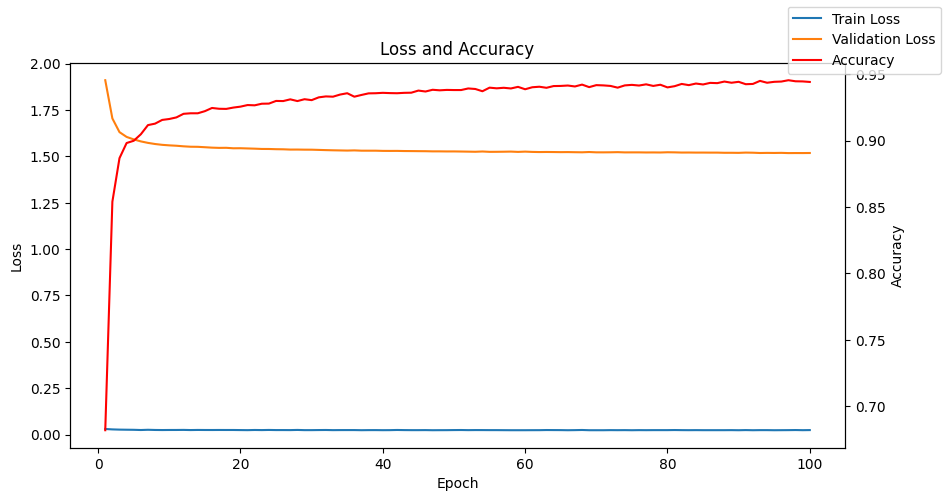

In [10]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(epochs_range, train_losses, label='Train Loss')
ax1.plot(epochs_range, validation_losses, label='Validation Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')

ax2 = ax1.twinx()
ax2.plot(epochs_range, accuracies, label='Accuracy', color='r')
ax2.set_ylabel('Accuracy')

plt.title('Loss and Accuracy')
fig.legend()
plt.show()

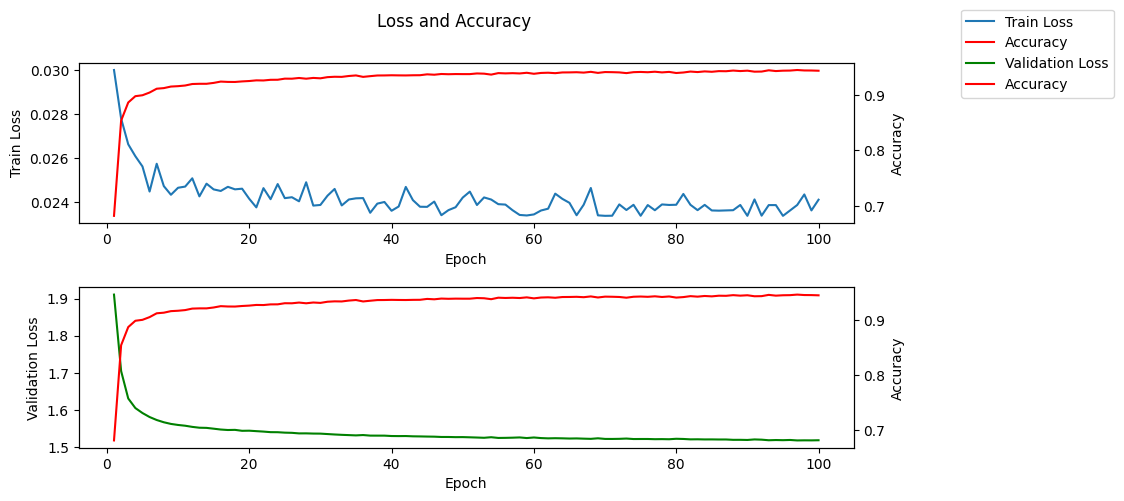

In [11]:
fig = plt.figure(figsize=(10, 5))
ax1 = fig.add_subplot(211)
ax1.plot(epochs_range, train_losses, label='Train Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Train Loss')

ax2 = ax1.twinx()
ax2.plot(epochs_range, accuracies, label='Accuracy', color='r')
ax2.set_ylabel('Accuracy')

ax3 = fig.add_subplot(212)
ax3.plot(epochs_range, validation_losses, label='Validation Loss', color='g')
ax4 = ax3.twinx()
ax3.set_xlabel('Epoch')
ax3.set_ylabel('Validation Loss')
ax4.plot(epochs_range, accuracies, label='Accuracy', color='r')
ax4.set_ylabel('Accuracy')

fig.suptitle('Loss and Accuracy')
fig.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.subplots_adjust(hspace=0.4)
plt.show()

# Influences

In [12]:
# Loading data
mnist_influences = save_objs_dict["mnist_influences"]
validate_list = save_objs_dict["validate_list"]
rand_list = save_objs_dict["rand_list"]


validate_dict = {
    "validate_accuracies": [],
    "validate_train_losses": [],
    "validate_validation_losses": []
}

rand_dict = {
    "rand_validate_accuracies": [],
    "rand_validate_train_losses": [],
    "rand_validate_validation_losses": []
}

for ckpt_idx, _ in enumerate(checkpoint_labels):
    validate_dict["validate_accuracies"].append(validate_list[ckpt_idx].accuracies)
    validate_dict["validate_train_losses"].append(validate_list[ckpt_idx].train_losses)
    validate_dict["validate_validation_losses"].append(validate_list[ckpt_idx].validation_losses)

    rand_dict["rand_validate_accuracies"].append(rand_list[ckpt_idx].accuracies)
    rand_dict["rand_validate_train_losses"].append(rand_list[ckpt_idx].train_losses)
    rand_dict["rand_validate_validation_losses"].append(rand_list[ckpt_idx].validation_losses)

In [13]:
def top_or_least_influences(ckpt_influences, train_dataset, num_per_row=10, descending=True):
    ckpt_num = len(ckpt_influences)
    # fig, ax = plt.subplots(ckpt_num, num_per_row, figsize=(20, 20))
    ckpt_imgs = []
    for ckpt, influences in enumerate(ckpt_influences):
        sorted_influences = torch.argsort(torch.from_numpy(influences), descending=descending)
        top_indexes = sorted_influences[:num_per_row]
        top_influential_train_data = [train_dataset[index] for index in top_indexes]
        ckpt_imgs.append(top_influential_train_data)
    return ckpt_imgs
    
mnist_ckpt_imgs = top_or_least_influences(mnist_influences, mnist_train, num_per_row=20)
num_data = len(mnist_train)
x_vals =  list(range(1, num_epochs+1))

In [14]:
checkpoints_filepaths = [os.path.join(dir_ckpt, "DigitNet", f"DigitNet_epoch_{epoch}_{epoch/num_epochs}.pth") for epoch in checkpoint_labels]

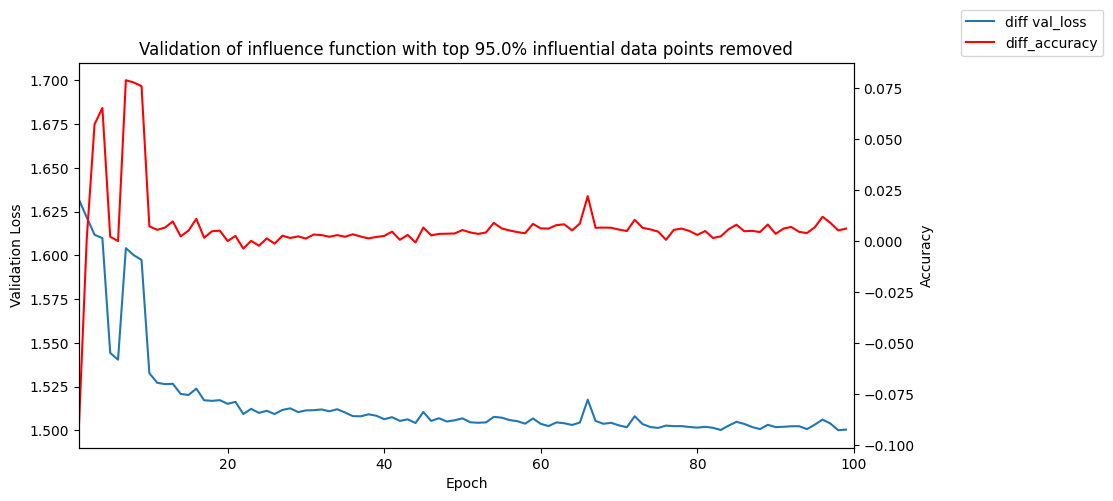

In [15]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
def concat_ckpt_metrics(metrics, ckpt_labels):
    integrate_metrics = []
    for i, metric in enumerate(metrics):
        prev_ckpt = ckpt_labels[i-1] if i > 0 else 0
        integrate_metrics.append(metric[prev_ckpt:])
    return np.concatenate(integrate_metrics)

diff_val_loss = concat_ckpt_metrics(validate_dict["validate_validation_losses"], checkpoint_labels) - concat_ckpt_metrics(rand_dict["rand_validate_train_losses"], checkpoint_labels) # suppose positive
diff_accuracy = concat_ckpt_metrics(rand_dict["rand_validate_accuracies"], checkpoint_labels) - concat_ckpt_metrics(validate_dict["validate_accuracies"], checkpoint_labels) # suppose positive

ax1.plot(diff_val_loss, label='diff val_loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Validation Loss')

ax2 = ax1.twinx()
ax2.plot(diff_accuracy, label='diff_accuracy', color='r')
ax2.set_ylabel('Accuracy')
plt.title(f'Validation of influence function with top {np.round(1-p, 2)*100}% influential data points removed')
fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

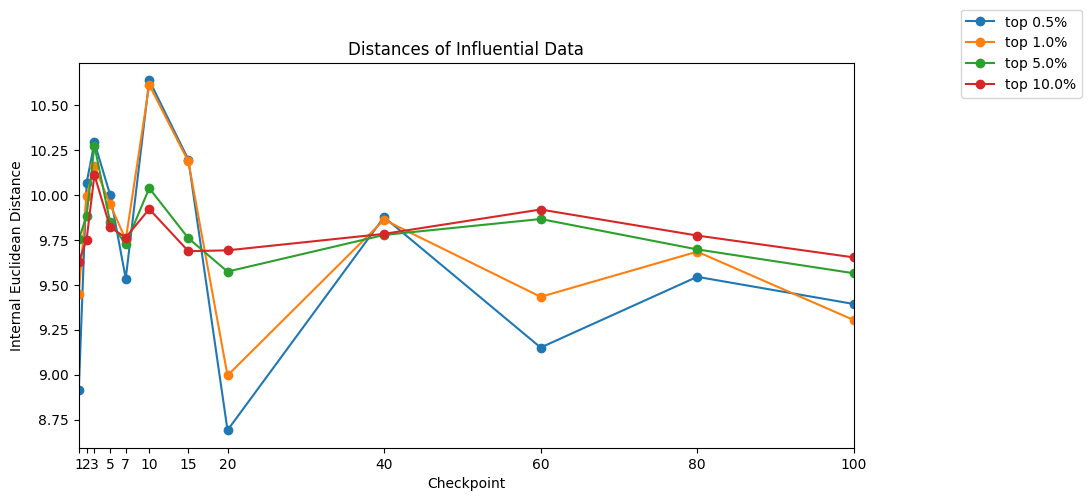

In [16]:
def calc_inter_dist(imgs):
    distances = euclidean_distances(imgs, imgs)
    mean_distance = np.mean(distances)
    return mean_distance

# Calculate distance of influential points towards other images
def calc_external_dist(inf_imgs, other_imgs):
    distances = euclidean_distances(inf_imgs, other_imgs)
    mean_distance = np.mean(distances)
    return mean_distance

# test selecting 0.5% 1% 5% 10% influential points
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
plt.title("Distances of Influential Data")
for p in [0.005, 0.01, 0.05, 0.1]:
    mnist_ckpt_imgs = top_or_least_influences(mnist_influences, mnist_train, num_per_row=int(p*num_data))
    inter_distances = []
    for ckpt, ckpt_imgs in enumerate(mnist_ckpt_imgs):
        ckpt_imgs = np.array([img[0] for img in ckpt_imgs])
        # print(f"checkpoint: {ckpt}, shape:{ckpt_imgs.shape}")
        mean_dist = calc_inter_dist(ckpt_imgs)
        inter_distances.append(mean_dist)
    ax1.plot(checkpoint_labels, inter_distances, 'o-', label=f"top {p*100}%")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Internal Euclidean Distance")
ax1.set_xticks(checkpoint_labels)
fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

100%|██████████| 12/12 [00:04<00:00,  2.60it/s]


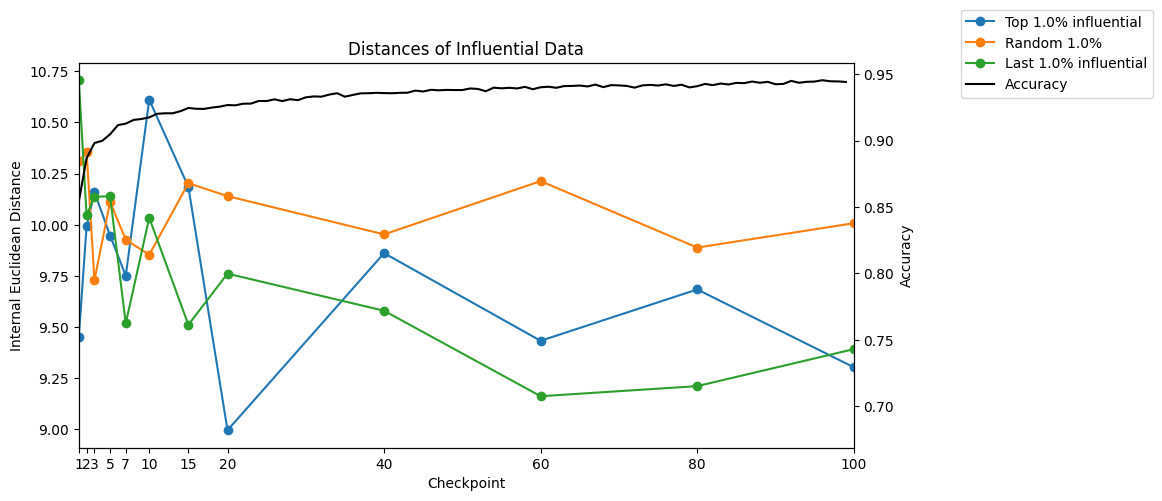

In [17]:
p = 0.01
def random_p_data(checkpoint_influences, train_dataset, num_data, p=0.01):
    checkpoints_data = []
    for _ in tqdm(checkpoint_influences):
        num_select = int(p * num_data)
        random_data = random.sample(list(train_dataset), num_select)
        checkpoints_data.append(random_data)
    return checkpoints_data

num_data = len(mnist_train)
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
plt.title("Distances of Influential Data")
mnist_ckpt_imgs = top_or_least_influences(mnist_influences, mnist_train, num_per_row=int(p*num_data))
top_inf_inter_distances = []
for ckpt_imgs in mnist_ckpt_imgs:
    ckpt_imgs = np.array([img[0] for img in ckpt_imgs])
    mean_dist = calc_inter_dist(ckpt_imgs)
    top_inf_inter_distances.append(mean_dist)
ax1.plot(checkpoint_labels, top_inf_inter_distances, 'o-', label=f"Top {p*100}% influential")

random_inter_distances = []
random_data = random_p_data(mnist_influences, mnist_train, len(mnist_train), p)
for data in random_data:
    ckpt_imgs = np.array([img[0] for img in data])
    mean_dist = calc_inter_dist(ckpt_imgs)
    random_inter_distances.append(mean_dist)
ax1.plot(checkpoint_labels, random_inter_distances, 'o-', label=f"Random {p*100}%")

# random_inter_distances = []
# random_data = random_p_data(mnist_influences, mnist_train, len(mnist_train), 0.01)
# for data in random_data:
#     ckpt_imgs = np.array([img[0] for img in data])
#     mean_dist = calc_inter_dist(ckpt_imgs)
#     random_inter_distances.append(mean_dist)
# ax1.plot(checkpoint_labels, random_inter_distances, 'o-', label="Random 1%")

last_inter_distances = []
for ckpt_imgs in top_or_least_influences(mnist_influences, mnist_train, int(p*num_data), descending=False):
    ckpt_imgs = np.array([img[0] for img in ckpt_imgs])
    mean_dist = calc_inter_dist(ckpt_imgs)
    last_inter_distances.append(mean_dist)
ax1.plot(checkpoint_labels, last_inter_distances, 'o-', label=f"Last {p*100}% influential")

ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Internal Euclidean Distance")
ax1.set_xticks(checkpoint_labels)
ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')
fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

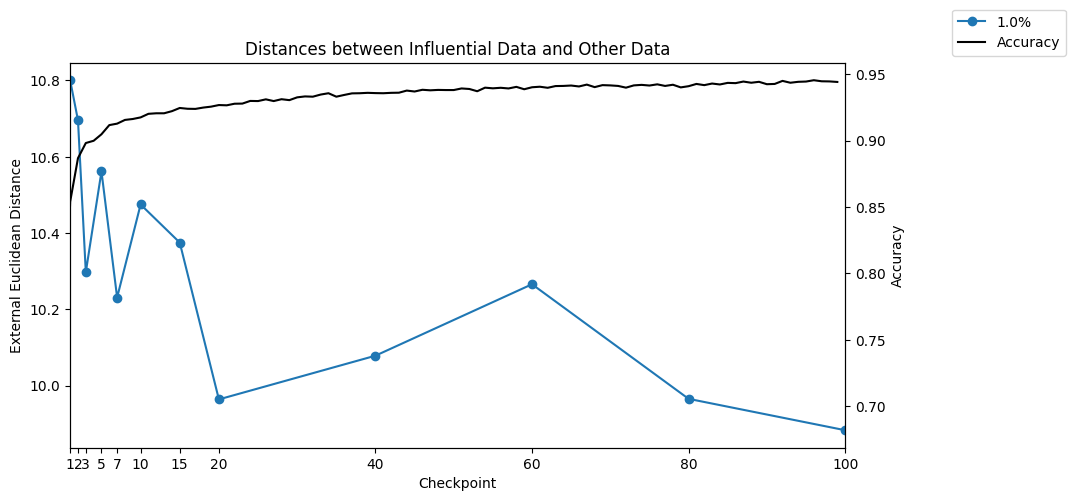

In [18]:
# Euclidean distance from influential points to other points
p = 0.01

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
plt.title("Distances between Influential Data and Other Data")
distances = []
for i in range(len(checkpoint_labels)):
    inf_imgs = np.array([img[0] for img in mnist_ckpt_imgs[i]])
    rand_imgs = np.array([img[0] for img in random_data[i]])
    mean_dist = calc_external_dist(inf_imgs, rand_imgs)
    distances.append(mean_dist)
    
ax1.plot(checkpoint_labels, distances, 'o-', label=f"{p*100}%")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("External Euclidean Distance")
ax1.set_xticks(checkpoint_labels)
ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')
fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

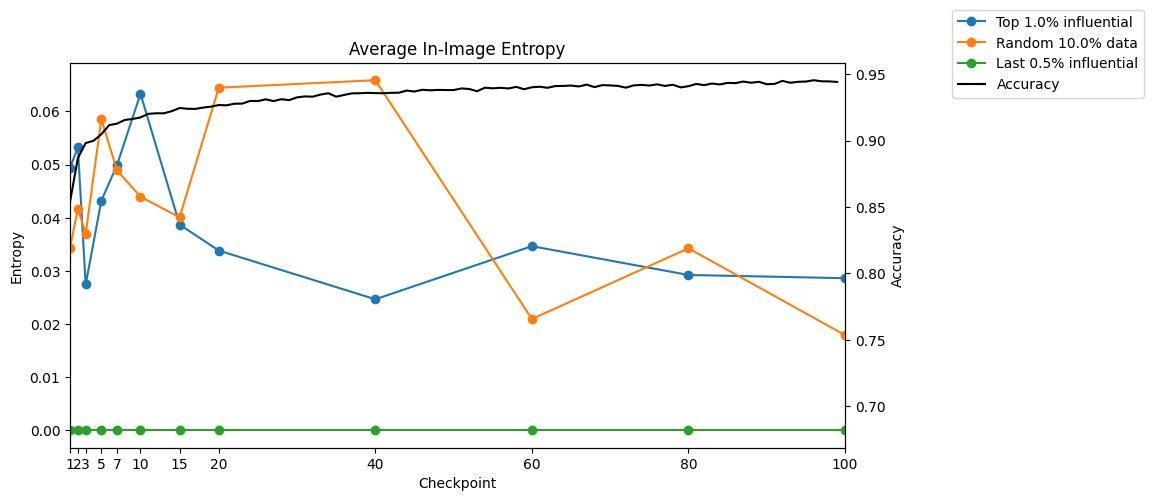

In [19]:
def calculate_entropy(image):
    hist, _ = np.histogram(image[0], bins=256, range=(0, 256))
    probabilities = hist / hist.sum()
    return -np.sum(probabilities * np.log2(probabilities + 1e-20))

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))

entropies = []
for imgs in mnist_ckpt_imgs:
    ckpt_entropies = [calculate_entropy(img) for img in imgs]
    mean_entropy = np.mean(ckpt_entropies)
    entropies.append(mean_entropy)
ax1.plot(checkpoint_labels, entropies, 'o-', label=f"Top {p*100}% influential")

randimgs_entropies = []
for data in random_data:
    ckpt_entropies = [calculate_entropy(img) for img in data]
    mean_entropy = np.mean(ckpt_entropies)
    randimgs_entropies.append(mean_entropy)
ax1.plot(checkpoint_labels, randimgs_entropies, 'o-', label=f"Random {p*10*100}% data")


last_inf_entropies = []
for ckpt_imgs in top_or_least_influences(mnist_influences, mnist_train, int(p*num_data), descending=False):
    last_inf_entropy = [calculate_entropy(img[0]) for img in ckpt_imgs]
    mean_entropy = np.mean(last_inf_entropy)
    last_inf_entropies.append(mean_entropy)
ax1.plot(checkpoint_labels, last_inf_entropies, 'o-', label="Last 0.5% influential")

ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Entropy")
ax1.set_xticks(checkpoint_labels)
plt.title("Average In-Image Entropy")
ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')
fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

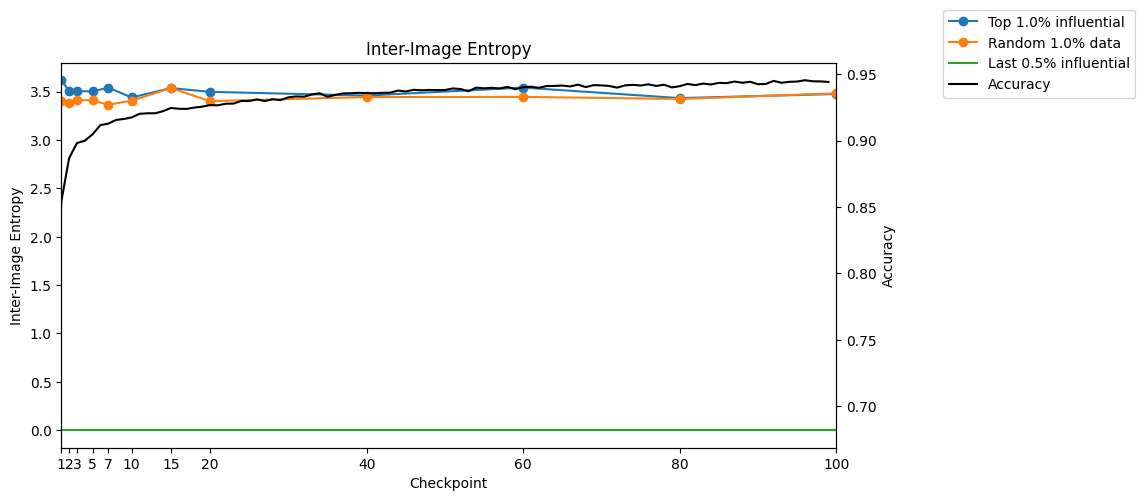

In [20]:
from scipy.spatial.distance import pdist
from scipy.stats import entropy

def image_pairwise_entropy(features):
    pairwise_distances = pdist(features, metric='cosine')
    distance_probs, _ = np.histogram(pairwise_distances, bins=50, density=True)
    distance_probs = distance_probs / np.sum(distance_probs)
    return entropy(distance_probs)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))

top_inf_pw_entropies = []
for imgs in mnist_ckpt_imgs:
    imgs = np.array([img[0] for img in imgs])
    ckpt_entropies = image_pairwise_entropy(imgs)
    top_inf_pw_entropies.append(ckpt_entropies)
ax1.plot(checkpoint_labels, top_inf_pw_entropies, 'o-', label=f"Top {p*100}% influential")

randimgs_pw_entropies = []
for data in random_data:
    imgs = np.array([img[0] for img in data])
    ckpt_entropies = image_pairwise_entropy(imgs)
    randimgs_pw_entropies.append(ckpt_entropies)
ax1.plot(checkpoint_labels, randimgs_pw_entropies, 'o-', label=f"Random {p*100}% data")


last_inf_pw_entropies = []
for ckpt_imgs in top_or_least_influences(mnist_influences, mnist_train, int(p*num_data), descending=False):
    last_inf_entropy = [img[0] for img in ckpt_imgs]
    ckpt_entropies = image_pairwise_entropy(last_inf_entropy)
    last_inf_pw_entropies.append(mean_entropy)
ax1.plot(checkpoint_labels, last_inf_pw_entropies, label="Last 0.5% influential")

ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Inter-Image Entropy")
plt.title("Inter-Image Entropy")
ax1.set_xticks(checkpoint_labels)
ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')
fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

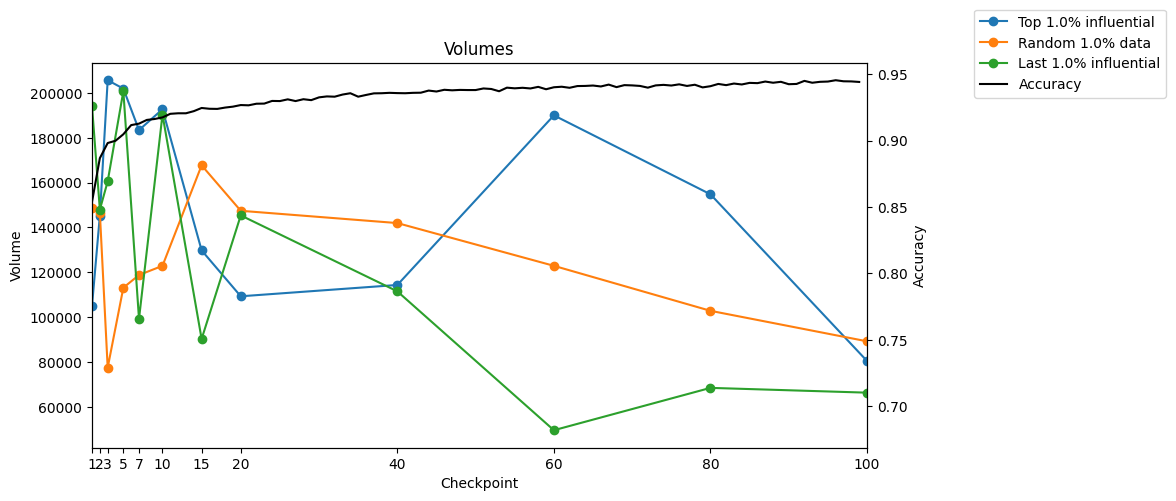

In [21]:
from sklearn.decomposition import PCA

def volume(images):
    return np.sqrt(np.linalg.det(images.T@images))

def pca(x, components):
    x_std = (x - np.mean(x, axis=0)) / (np.std(x, axis=0) + 1e-8)
    pca = PCA(n_components=components)
    pca.fit(x_std)
    return pca.components_

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))

top_inf_volumes = []
for ckpt_imgs in mnist_ckpt_imgs:
    ckpt_imgs = np.array([img[0] for img in ckpt_imgs])
    W = pca(ckpt_imgs, 4)
    Z_imgs = ckpt_imgs @ W.T
    # print(f"Z_imgs: {Z_imgs.shape}, volume: {volume(Z_imgs)}")
    # print(f"checkpoint: {ckpt_imgs.shape}")
    top_inf_volumes.append(volume(Z_imgs))
ax1.plot(checkpoint_labels, top_inf_volumes, 'o-', label=f"Top {p*100}% influential")

randimgs_volumes = []
for data in random_data:
    ckpt_imgs = np.array([img[0] for img in data])
    W = pca(ckpt_imgs, 4)
    Z_imgs = ckpt_imgs @W.T
    randimgs_volumes.append(volume(Z_imgs))
ax1.plot(checkpoint_labels, randimgs_volumes, 'o-', label=f"Random {p*100}% data")


last_inf_volumes = []
for ckpt_imgs in top_or_least_influences(mnist_influences, mnist_train, int(p*num_data), descending=False):
    ckpt_imgs = np.array([img[0] for img in ckpt_imgs])
    W = pca(ckpt_imgs, 4)
    Z_imgs = ckpt_imgs @W.T
    last_inf_volumes.append(volume(Z_imgs))
ax1.plot(checkpoint_labels, last_inf_volumes, 'o-', label=f"Last {p*100}% influential")

ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Volume")
ax1.set_xticks(checkpoint_labels)
ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')
fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.title("Volumes")
plt.show()

# Retrain on Top n IP

In [22]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device: ", device)

Device:  cpu


In [23]:
class DigitNet(nn.Module):
    def __init__(self, input_dimensions=784, num_classes=10): 
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dimensions, 512),
            nn.ReLU(),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes),
            nn.Softmax(dim=-1)
            )
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.model(x)

Checkpoint loaded at epoch 1 with completion rate 0.01
Checkpoint loaded at epoch 2 with completion rate 0.02
Checkpoint loaded at epoch 3 with completion rate 0.03
Checkpoint loaded at epoch 5 with completion rate 0.05
Checkpoint loaded at epoch 7 with completion rate 0.07
Checkpoint loaded at epoch 10 with completion rate 0.1
Checkpoint loaded at epoch 15 with completion rate 0.15
Checkpoint loaded at epoch 20 with completion rate 0.2
Checkpoint loaded at epoch 40 with completion rate 0.4
Checkpoint loaded at epoch 60 with completion rate 0.6
Checkpoint loaded at epoch 80 with completion rate 0.8
Checkpoint loaded at epoch 100 with completion rate 1.0
train_losses for top: [1.8679975271224976, 1.9352638721466064, 1.9026676416397095, 1.926600456237793, 1.9497756958007812, 1.8859525918960571, 1.877745270729065, 1.794109582901001, 1.701101303100586, 1.5810223817825317, 1.5808494091033936, 1.6170141696929932]
Checkpoint loaded at epoch 1 with completion rate 0.01
Checkpoint loaded at epo

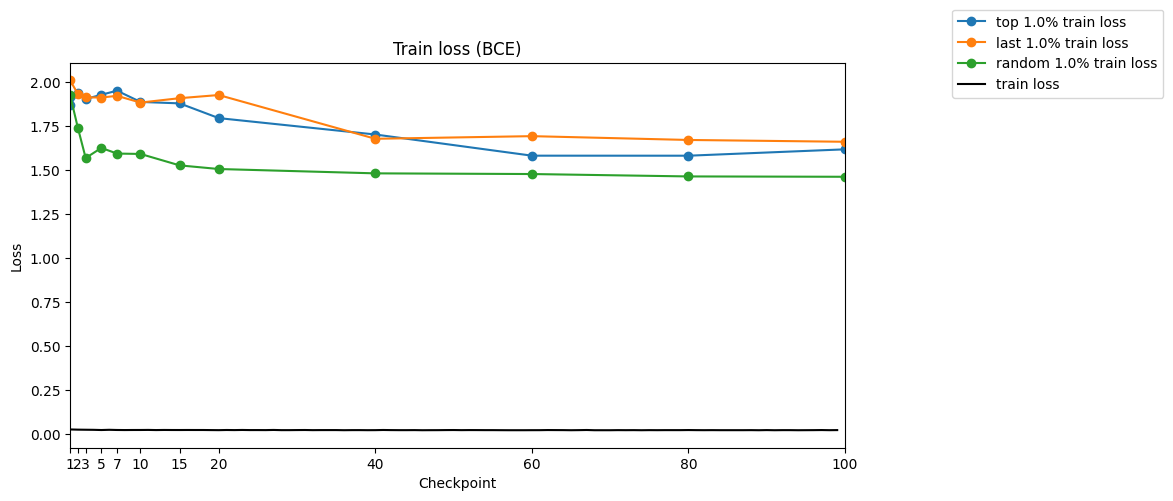

In [24]:
mnist_ckpt_imgs = top_or_least_influences(mnist_influences, mnist_train, num_per_row=int(p*num_data))
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
labels = ["top", "last", "random"]
last_ckpts_embeds = top_or_least_influences(mnist_influences, mnist_train, int(p*num_data), descending=False)
for j, ckpts_embeds in enumerate([mnist_ckpt_imgs, last_ckpts_embeds, random_data]):
    train_losses = [] # BCE loss
    for i, embeds in enumerate(ckpts_embeds):
        checkpoint = checkpoints_filepaths[i]
        inputs = torch.tensor(np.array([embed[0] for embed in embeds]))
        expect_val = torch.tensor([embed[1] for embed in embeds], device=device)
        optimizer = torch.optim.Adam(DigitNet().parameters(), lr=0.0001)
        model, optimizer, _, _ = load_checkpoint(DigitNet().to(device), optimizer, checkpoint)
        loss_fn = nn.CrossEntropyLoss()
        outputs = model(inputs)
        loss = loss_fn(outputs, expect_val)
        train_losses.append(loss.item())
    print(f"train_losses for {labels[j]}: {train_losses}")
    ax1.plot(checkpoint_labels, train_losses, 'o-', 
            label=f"{labels[j]} {p*100}% train loss")

plt.title("Train loss (BCE)")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Loss")
ax1.set_xticks(checkpoint_labels)
train_losses = save_objs_dict["model_eval_obj"].train_losses
ax1.plot(train_losses, label="train loss", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

Checkpoint loaded at epoch 1 with completion rate 0.01
Checkpoint loaded at epoch 2 with completion rate 0.02
Checkpoint loaded at epoch 3 with completion rate 0.03
Checkpoint loaded at epoch 5 with completion rate 0.05
Checkpoint loaded at epoch 7 with completion rate 0.07
Checkpoint loaded at epoch 10 with completion rate 0.1
Checkpoint loaded at epoch 15 with completion rate 0.15
Checkpoint loaded at epoch 20 with completion rate 0.2
Checkpoint loaded at epoch 40 with completion rate 0.4
Checkpoint loaded at epoch 60 with completion rate 0.6
Checkpoint loaded at epoch 80 with completion rate 0.8
Checkpoint loaded at epoch 100 with completion rate 1.0
Checkpoint loaded at epoch 1 with completion rate 0.01
Checkpoint loaded at epoch 2 with completion rate 0.02
Checkpoint loaded at epoch 3 with completion rate 0.03
Checkpoint loaded at epoch 5 with completion rate 0.05
Checkpoint loaded at epoch 7 with completion rate 0.07
Checkpoint loaded at epoch 10 with completion rate 0.1
Checkpoi

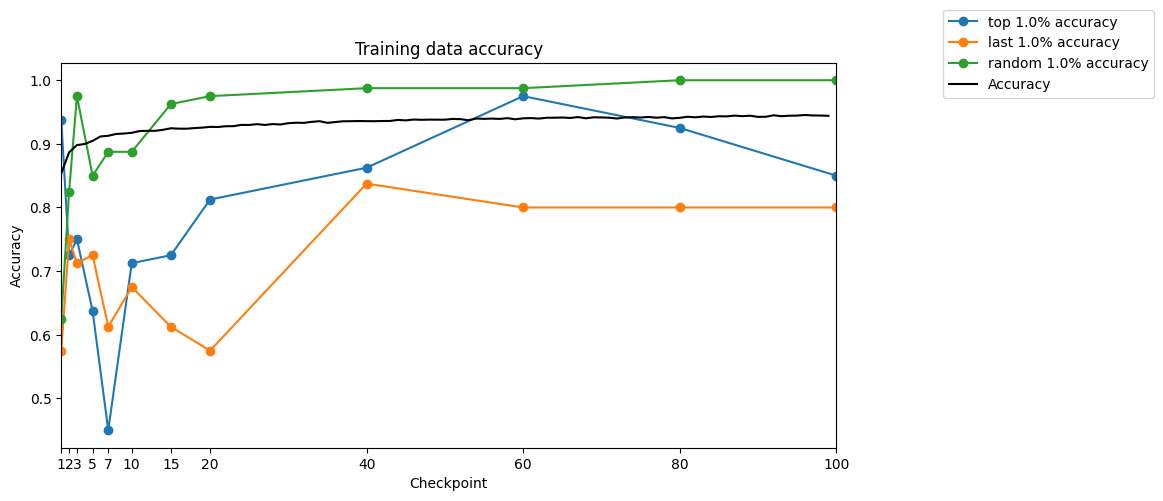

In [25]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))

labels = ["top", "last", "random"]
for j, ckpts_embeds in enumerate([mnist_ckpt_imgs, last_ckpts_embeds, random_data]):
    accuracies = []
    
    for i, embeds in enumerate(ckpts_embeds):
        checkpoint = checkpoints_filepaths[i]
        inputs = torch.tensor(np.array([embed[0] for embed in embeds]), dtype=torch.float32, device=device)
        expect_val = torch.tensor([embed[1] for embed in embeds], device=device)
        model, optimizer, _, _ = load_checkpoint(DigitNet().to(device), optimizer, checkpoint)
        outputs = model(inputs)
        predictions = torch.argmax(outputs, dim=-1)
        accuracy = (predictions == expect_val).sum() / len(expect_val)
        accuracies.append(accuracy.item())
    ax1.plot(checkpoint_labels, accuracies, 'o-', 
             label=f"{labels[j]} {p*100}% accuracy")

plt.title("Training data accuracy")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Accuracy")
ax1.set_xticks(checkpoint_labels)
accuracies = save_objs_dict["model_eval_obj"].accuracies
ax1.plot(accuracies, label="Accuracy", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

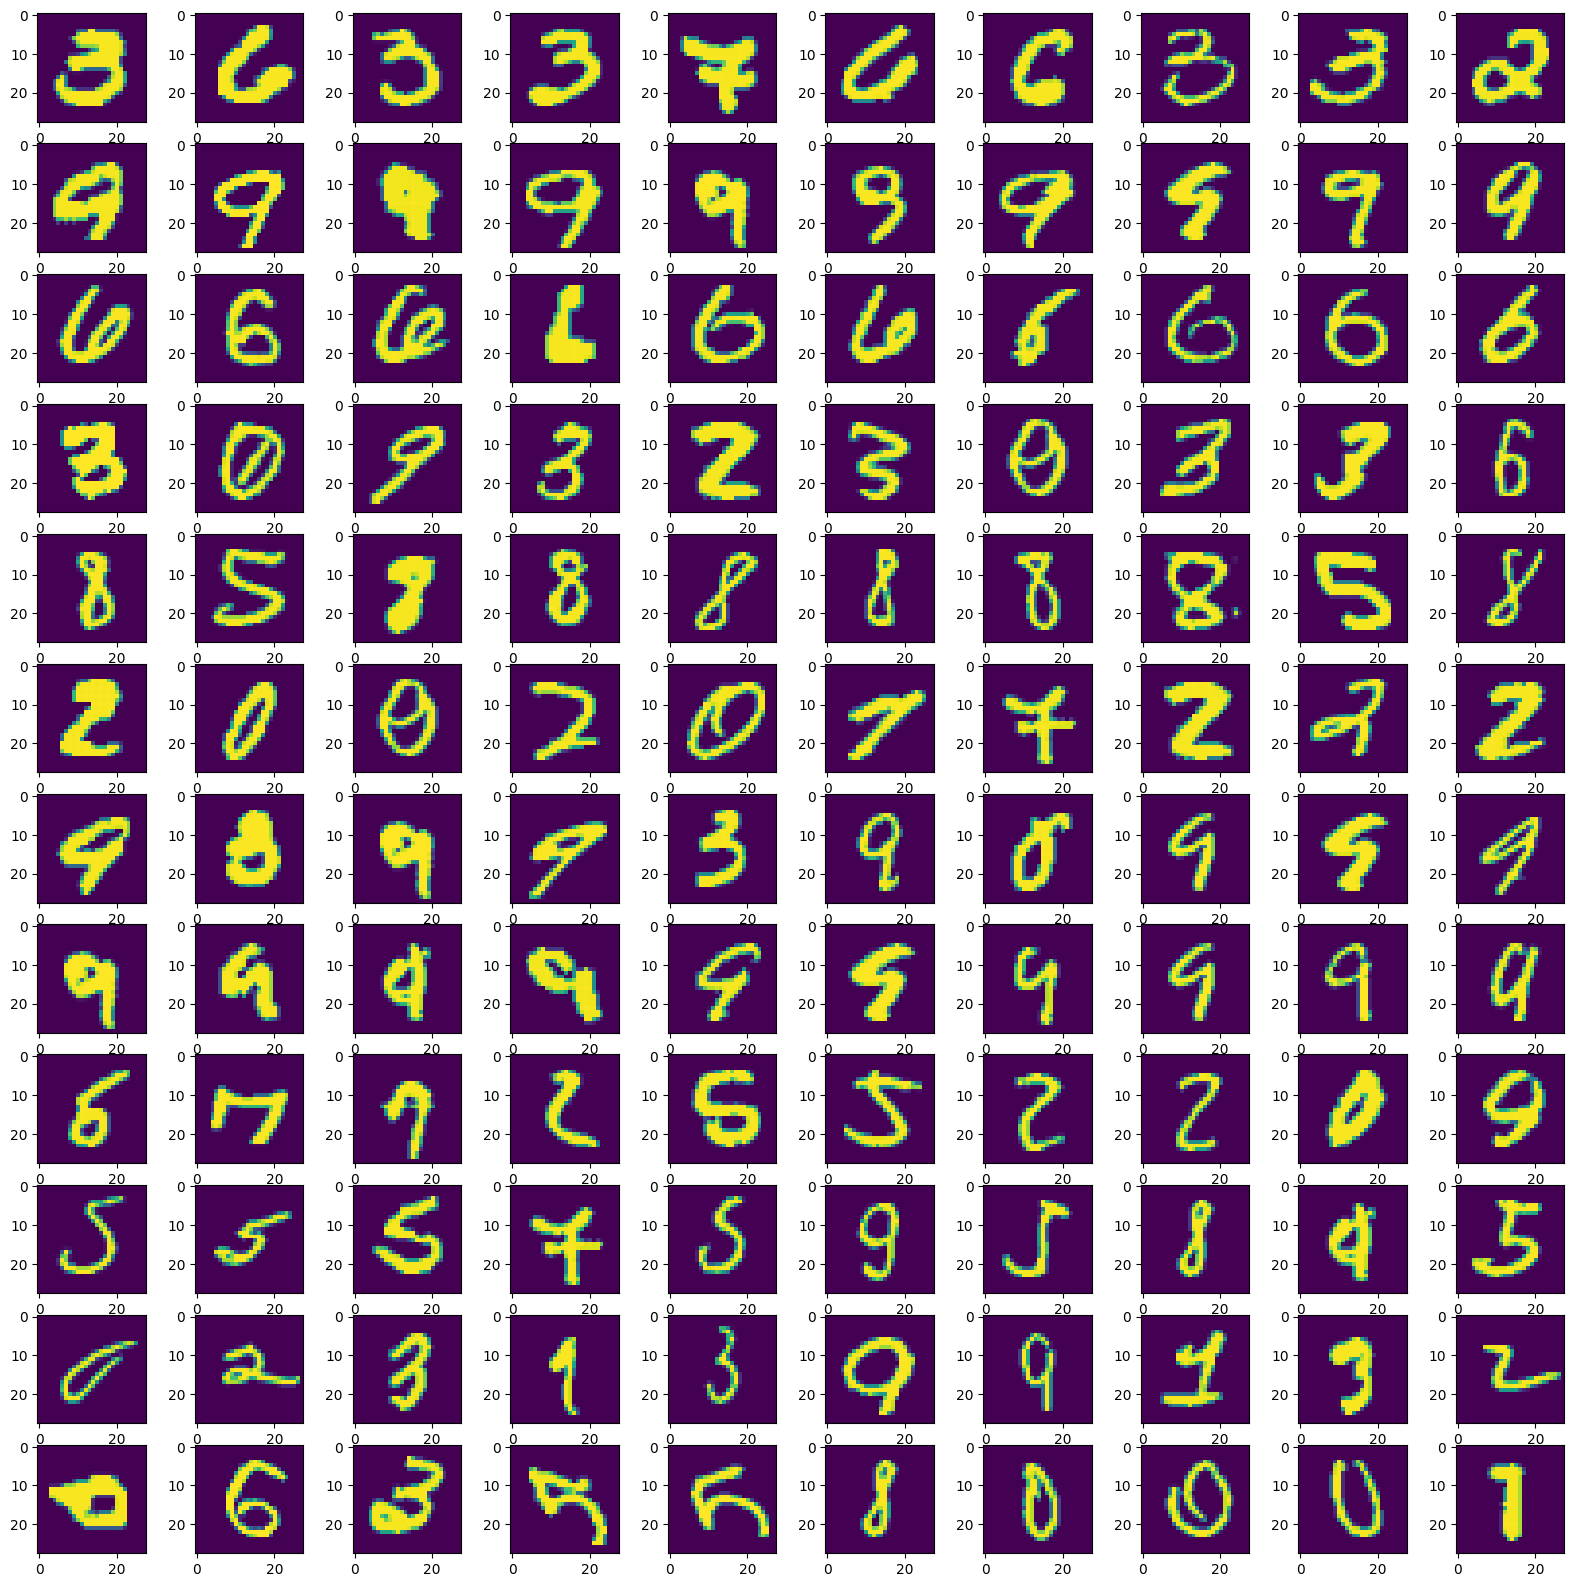

In [26]:
# Least influtial points qualitative check
fig, ax = plt.subplots(len(last_ckpts_embeds), 10, figsize=(20, 20))
for i in range(len(last_ckpts_embeds)):
    for j in range(10):
        ax[i, j].imshow(last_ckpts_embeds[i][j][0].reshape(28, 28))
plt.show()

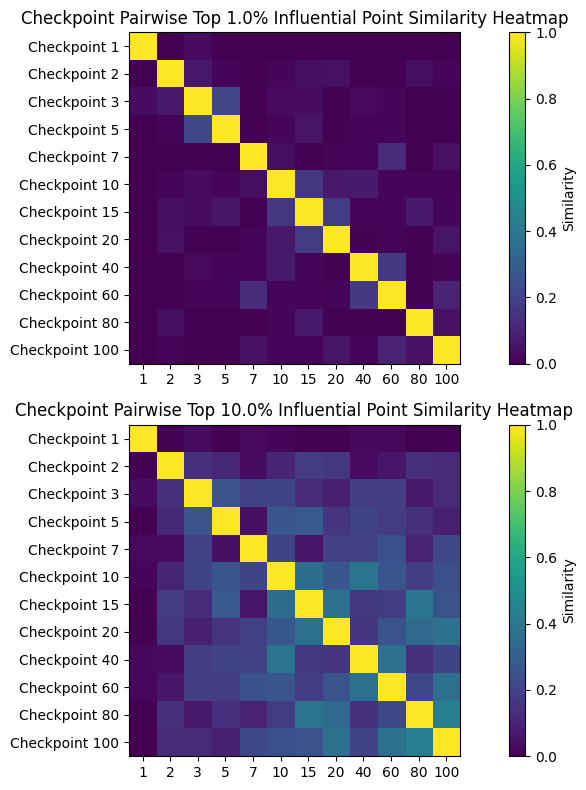

In [27]:
def pairwise_similarity(ckpts_indices):
    similarities = []
    for i in range(len(ckpts_indices)):
        similarity = []
        for j in range(len(ckpts_indices)):
            common = len(set(ckpts_indices[i]).intersection(set(ckpts_indices[j])))
            union = len(set(ckpts_indices[i]).union(set(ckpts_indices[j])))
            similarity.append(common / union)
        similarities.append(similarity)
    return np.array([np.array(sim) for sim in similarities])

def top_inf_indices(ckpts_influences, num_per_row):
    top_inf_indices = []
    for ckpt_influences in ckpts_influences:
        sorted_influences = torch.argsort(torch.from_numpy(ckpt_influences), descending=True)
        top_indexes = sorted_influences[:num_per_row].tolist()
        top_inf_indices.append(top_indexes)
    return top_inf_indices
pw_similarities_lowp = pairwise_similarity(top_inf_indices(mnist_influences, int(p*num_data)))
pw_similarities_highp = pairwise_similarity(top_inf_indices(mnist_influences, int(0.1*num_data)))

fig = plt.figure(figsize=(10, 8))
ax1 = fig.add_subplot(211)
im1 = ax1.imshow(pw_similarities_lowp, cmap='viridis', interpolation='nearest')
fig.colorbar(im1, ax=ax1, label='Similarity')
ax1.set_xticks(range(len(checkpoint_labels)), checkpoint_labels)
ax1.set_yticks(range(len(checkpoint_labels)), [f'Checkpoint {i}' for i in checkpoint_labels])
ax1.set_title(f'Checkpoint Pairwise Top {p*100}% Influential Point Similarity Heatmap')

ax2 = fig.add_subplot(212)
im2 = ax2.imshow(pw_similarities_highp, cmap='viridis', interpolation='nearest')
fig.colorbar(im2, ax=ax2, label='Similarity')
ax2.set_xticks(range(len(checkpoint_labels)), checkpoint_labels)
ax2.set_yticks(range(len(checkpoint_labels)), [f'Checkpoint {i}' for i in checkpoint_labels])
ax2.set_title(f'Checkpoint Pairwise Top {0.1*100}% Influential Point Similarity Heatmap')
plt.tight_layout()

plt.show()